<a href="https://colab.research.google.com/github/jannatulferdus182003/machine-larning/blob/main/Copy_of_Breast_Cancer_Classification_Full_Code_One_Upload.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Breast Cancer Diagnosis Using Supervised Machine Learning

**pandas** is a Python library for data manipulation and analysis. It provides data structures and operations for working with numerical tables and time series.

In this notebook, you will learn how to load the Breast Cancer dataset and explore, clean, and prepare it for supervised machine learning.

## 1.1 Installing and Importing Pandas

Run the cell below to install pandas if it is not already installed in your environment. In Google Colab, pandas is normally already installed, so this line is kept as a comment.

In [ ]:
#!pip install pandas

Import pandas under the conventional alias `pd`.

In [ ]:
import pandas as pd

## 1.2 Importing a Dataset

This notebook uses the Breast Cancer Wisconsin (Diagnostic) dataset, which contains diagnosis labels and diagnostic measurements.

Run the cell below and upload your `data.csv` file when prompted.

In [ ]:
from google.colab import files
uploaded = files.upload()  # Select your data.csv file only once

Saving data.csv to data.csv


Load the uploaded CSV into a pandas DataFrame and print it.

In [ ]:
import io

# Read the CSV file selected in the upload cell above.
csv_filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[csv_filename]))
print(df)

           id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0      842302         M        17.99         10.38          122.80     1001.0   
1      842517         M        20.57         17.77          132.90     1326.0   
2    84300903         M        19.69         21.25          130.00     1203.0   
3    84348301         M        11.42         20.38           77.58      386.1   
4    84358402         M        20.29         14.34          135.10     1297.0   
..        ...       ...          ...           ...             ...        ...   
564    926424         M        21.56         22.39          142.00     1479.0   
565    926682         M        20.13         28.25          131.20     1261.0   
566    926954         M        16.60         28.08          108.30      858.1   
567    927241         M        20.60         29.33          140.10     1265.0   
568     92751         B         7.76         24.54           47.92      181.0   

     smoothness_mean  compa

## Setup: Import the remaining libraries

In [ ]:
import io
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, chi2, RFE, RFECV, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, precision_recall_curve,
    PrecisionRecallDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Step 1: Load the Dataset

### Implementation 1.1 — Read CSV file

In [ ]:
# If using the Colab upload cell above, df is already loaded.
# This displays the dataset variable created from the uploaded CSV.
df = df.copy()
print("CSV loaded successfully.")

CSV loaded successfully.


### Implementation 1.2 — Display the first few records (`head()`)

In [ ]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


### Implementation 1.3 — Check dataset dimensions (`shape`)

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Dataset shape:", df.shape)

Rows: 569
Columns: 33
Dataset shape: (569, 33)


### Implementation 1.4 — Display column names (`columns`)

In [ ]:
print(df.columns.tolist())

['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


### Implementation 1.5 — Inspect data types and non-null counts (`info()`)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

## Step 2: Inspect Data Quality

### Implementation 2.1 — Check missing values (`isnull().sum()`)

In [ ]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


### Implementation 2.2 — Count missing values in the whole dataset

In [ ]:
print("Total missing values:", int(df.isnull().sum().sum()))

Total missing values: 569


### Implementation 2.3 — Check duplicate records (`duplicated()`)

In [ ]:
print("Duplicate rows:", int(df.duplicated().sum()))

Duplicate rows: 0


### Implementation 2.4 — Remove duplicate records (`drop_duplicates()`)

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (569, 33)


### Implementation 2.5 — Generate descriptive statistics (`describe()`)

In [ ]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


### Implementation 2.6 — Identify unnecessary/non-predictive columns

In [ ]:
print("Possible ID columns:", [c for c in df.columns if c.lower() == "id"])
print("Possible empty extra columns:", [c for c in df.columns if c.lower().startswith("unnamed")])

Possible ID columns: ['id']
Possible empty extra columns: ['Unnamed: 32']


## Step 3: Define Features and Target

### Implementation 3.1 — Remove an empty `Unnamed` column if present

In [ ]:
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("unnamed")], errors="ignore")
print("Columns after removing empty extra columns:", df.columns.tolist())

Columns after removing empty extra columns: ['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


### Implementation 3.2 — Separate the diagnosis target

In [ ]:
y_text = df["diagnosis"].copy()
print(y_text.value_counts())

diagnosis
B    357
M    212
Name: count, dtype: int64


### Implementation 3.3 — Convert diagnosis labels to numbers (`map()`)

In [ ]:
y = y_text.map({"B": 0, "M": 1})
print("Mapping: Benign (B) = 0, Malignant (M) = 1")
print(y.value_counts())

Mapping: Benign (B) = 0, Malignant (M) = 1
diagnosis
0    357
1    212
Name: count, dtype: int64


### Implementation 3.4 — Create input features and remove ID/target columns (`drop()`)

In [ ]:
X = df.drop(columns=["id", "diagnosis"], errors="ignore")
print("Feature matrix shape:", X.shape)
print("Number of input features:", X.shape[1])

Feature matrix shape: (569, 30)
Number of input features: 30


### Implementation 3.5 — Verify feature and target data

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing target labels:", int(y.isnull().sum()))
print("Feature columns:")
print(X.columns.tolist())

if y.isnull().any():
    raise ValueError("Unexpected diagnosis labels found. Check the diagnosis column.")

X shape: (569, 30)
y shape: (569,)
Missing target labels: 0
Feature columns:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


## Step 4: Perform Stratified Train-Test Split

### Implementation 4.1 — Split data into 80% training and 20% testing

In [ ]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training set:", X_train_raw.shape)
print("Testing set:", X_test_raw.shape)

Training set: (455, 30)
Testing set: (114, 30)


### Implementation 4.2 — Verify target distribution after stratification

In [ ]:
print("Training target counts:")
display(y_train.value_counts().rename(index={0: "Benign (B)", 1: "Malignant (M)"}))
print("Testing target counts:")
display(y_test.value_counts().rename(index={0: "Benign (B)", 1: "Malignant (M)"}))

Training target counts:


,count
diagnosis,
Benign (B),285
Malignant (M),170


Testing target counts:


,count
diagnosis,
Benign (B),72
Malignant (M),42


### Implementation 4.3 — Compare class proportions

In [ ]:
print("Training proportions:")
display(y_train.value_counts(normalize=True).rename(index={0: "Benign (B)", 1: "Malignant (M)"}))
print("Testing proportions:")
display(y_test.value_counts(normalize=True).rename(index={0: "Benign (B)", 1: "Malignant (M)"}))

Training proportions:


,proportion
diagnosis,
Benign (B),0.626374
Malignant (M),0.373626


Testing proportions:


,proportion
diagnosis,
Benign (B),0.631579
Malignant (M),0.368421


## Step 5: Handle Missing Values

### Implementation 5.1 — Check missing values in training features

In [ ]:
X_train_raw.isnull().sum().sort_values(ascending=False).head(10)

,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0
fractal_dimension_mean,0


### Implementation 5.2 — Create the median imputer

In [ ]:
imputer = SimpleImputer(strategy="median")
print("Median imputer created.")

Median imputer created.


### Implementation 5.3 — Fit imputer and transform training data

In [ ]:
X_train_imputed_array = imputer.fit_transform(X_train_raw)
print("Training data imputed.")

Training data imputed.


### Implementation 5.4 — Transform test data using the same imputer

In [ ]:
X_test_imputed_array = imputer.transform(X_test_raw)
print("Test data transformed using the training-fitted imputer.")

Test data transformed using the training-fitted imputer.


### Implementation 5.5 — Convert imputed arrays back to DataFrames

In [ ]:
feature_names = X.columns.tolist()
X_train_imputed = pd.DataFrame(X_train_imputed_array, columns=feature_names, index=X_train_raw.index)
X_test_imputed = pd.DataFrame(X_test_imputed_array, columns=feature_names, index=X_test_raw.index)

print("Missing values in imputed train:", int(X_train_imputed.isnull().sum().sum()))
print("Missing values in imputed test:", int(X_test_imputed.isnull().sum().sum()))

Missing values in imputed train: 0
Missing values in imputed test: 0


## Step 6: Scale Numerical Features

### Implementation 6.1 — Create MinMaxScaler

In [ ]:
scaler = MinMaxScaler()
print("MinMaxScaler created.")

MinMaxScaler created.


### Implementation 6.2 — Fit scaler and transform training features

In [ ]:
X_train_scaled_array = scaler.fit_transform(X_train_imputed)
print("Training features scaled.")

Training features scaled.


### Implementation 6.3 — Transform test features using the same scaler

In [ ]:
X_test_scaled_array = scaler.transform(X_test_imputed)
print("Test features scaled using the training-fitted scaler.")

### Implementation 6.4 — Restore feature names and inspect scaled data

In [ ]:
X_train_scaled = pd.DataFrame(X_train_scaled_array, columns=feature_names, index=X_train_imputed.index)
# Ensure X_test_scaled_array is generated using the fitted scaler
X_test_scaled_array = scaler.transform(X_test_imputed)
X_test_scaled = pd.DataFrame(X_test_scaled_array, columns=feature_names, index=X_test_imputed.index)
display(X_train_scaled.head())

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
10,0.427801,0.457558,0.407090,0.277540,0.193775,0.145114,0.077296,0.165159,0.236364,0.142585,...,0.400569,0.582623,0.365506,0.237122,0.309912,0.124002,0.116534,0.342784,0.272620,0.193362
170,0.252686,0.090632,0.242278,0.135992,0.399346,0.154684,0.093416,0.183897,0.454040,0.197246,...,0.198150,0.096482,0.182081,0.089437,0.444628,0.096351,0.099201,0.322715,0.248768,0.083104
407,0.277770,0.394319,0.268399,0.157370,0.128853,0.195632,0.143533,0.092793,0.262626,0.230932,...,0.230167,0.399520,0.205289,0.113203,0.150895,0.161355,0.146805,0.192474,0.181944,0.173619
430,0.374793,0.433548,0.402944,0.229692,0.366340,0.623029,0.640347,0.482654,0.495455,0.397034,...,0.299538,0.414446,0.373475,0.159138,0.467080,0.661398,0.720367,0.850515,0.256456,0.396563
27,0.550381,0.356442,0.541151,0.403181,0.316087,0.267530,0.349110,0.384245,0.321717,0.143008,...,0.475987,0.406183,0.445690,0.299302,0.413590,0.178916,0.275240,0.512027,0.152967,0.125738


## Step 7: Exploratory Data Analysis (EDA)

### Implementation 7.1 — Examine diagnosis class distribution (`value_counts()`)

In [ ]:
class_counts = y_text.value_counts()
display(class_counts.rename(index={"B": "Benign (B)", "M": "Malignant (M)"}).to_frame("Count"))

,Count
diagnosis,
Benign (B),357
Malignant (M),212


### Implementation 7.2 — Plot diagnosis class distribution (`countplot()`)

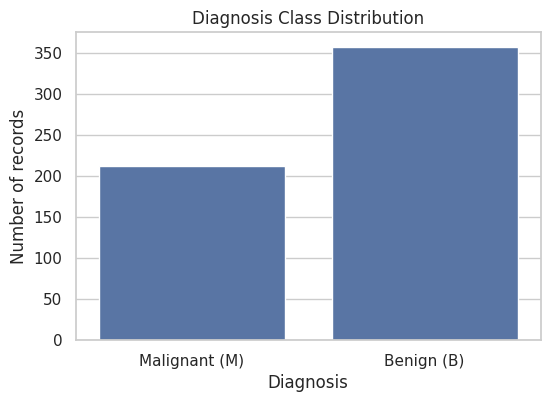

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_text.map({"B": "Benign (B)", "M": "Malignant (M)"}))
plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of records")
plt.show()

### Implementation 7.3 — Visualize a selected feature distribution (`violinplot()`)

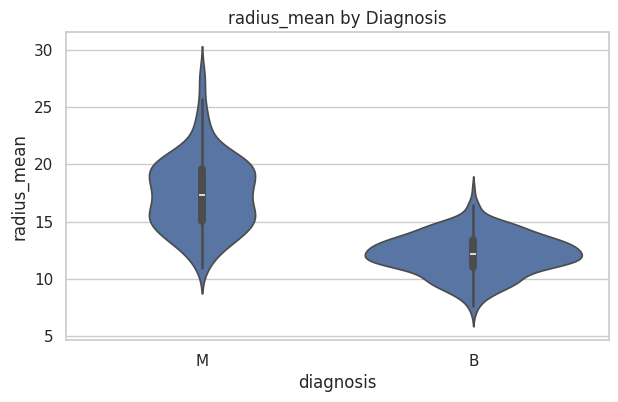

In [ ]:
eda_df = X.copy()
eda_df["diagnosis"] = y_text
feature_to_plot = "radius_mean"
if feature_to_plot in eda_df.columns:
    plt.figure(figsize=(7, 4))
    sns.violinplot(data=eda_df, x="diagnosis", y=feature_to_plot)
    plt.title(f"{feature_to_plot} by Diagnosis")
    plt.show()
else:
    print(f"{feature_to_plot} not found in this dataset.")

### Implementation 7.4 — Visualize feature distribution with a boxplot

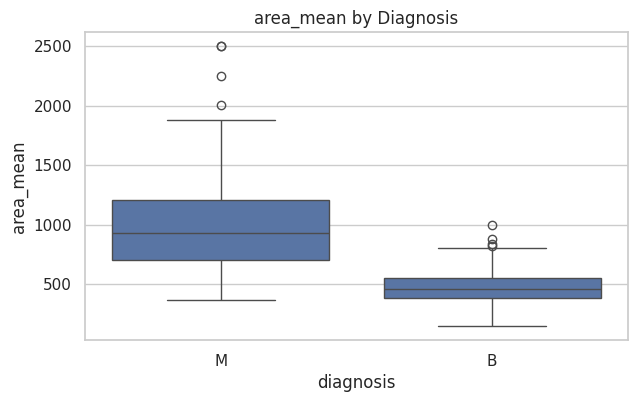

In [ ]:
feature_to_plot = "area_mean"
if feature_to_plot in eda_df.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=eda_df, x="diagnosis", y=feature_to_plot)
    plt.title(f"{feature_to_plot} by Diagnosis")
    plt.show()
else:
    print(f"{feature_to_plot} not found in this dataset.")

### Implementation 7.5 — Visualize feature distribution with a histogram (`histplot()`)

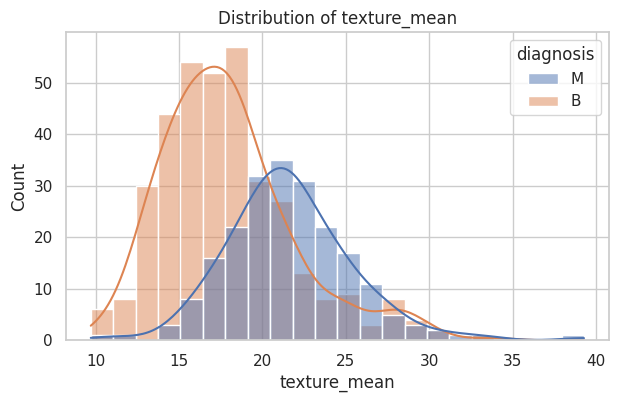

In [ ]:
feature_to_plot = "texture_mean"
if feature_to_plot in eda_df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=eda_df, x=feature_to_plot, hue="diagnosis", kde=True)
    plt.title(f"Distribution of {feature_to_plot}")
    plt.show()
else:
    print(f"{feature_to_plot} not found in this dataset.")

### Implementation 7.6 — Calculate feature correlations (`corr()`)

In [ ]:
train_correlation = X_train_imputed.corr()
display(train_correlation.iloc[:5, :5])

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean
radius_mean,1.000000,0.326358,0.997815,0.986740,0.188805
texture_mean,0.326358,1.000000,0.331800,0.318811,-0.011749
perimeter_mean,0.997815,0.331800,1.000000,0.985960,0.225840
area_mean,0.986740,0.318811,0.985960,1.000000,0.200033
smoothness_mean,0.188805,-0.011749,0.225840,0.200033,1.000000


### Implementation 7.7 — Plot correlation heatmap (`heatmap()`)

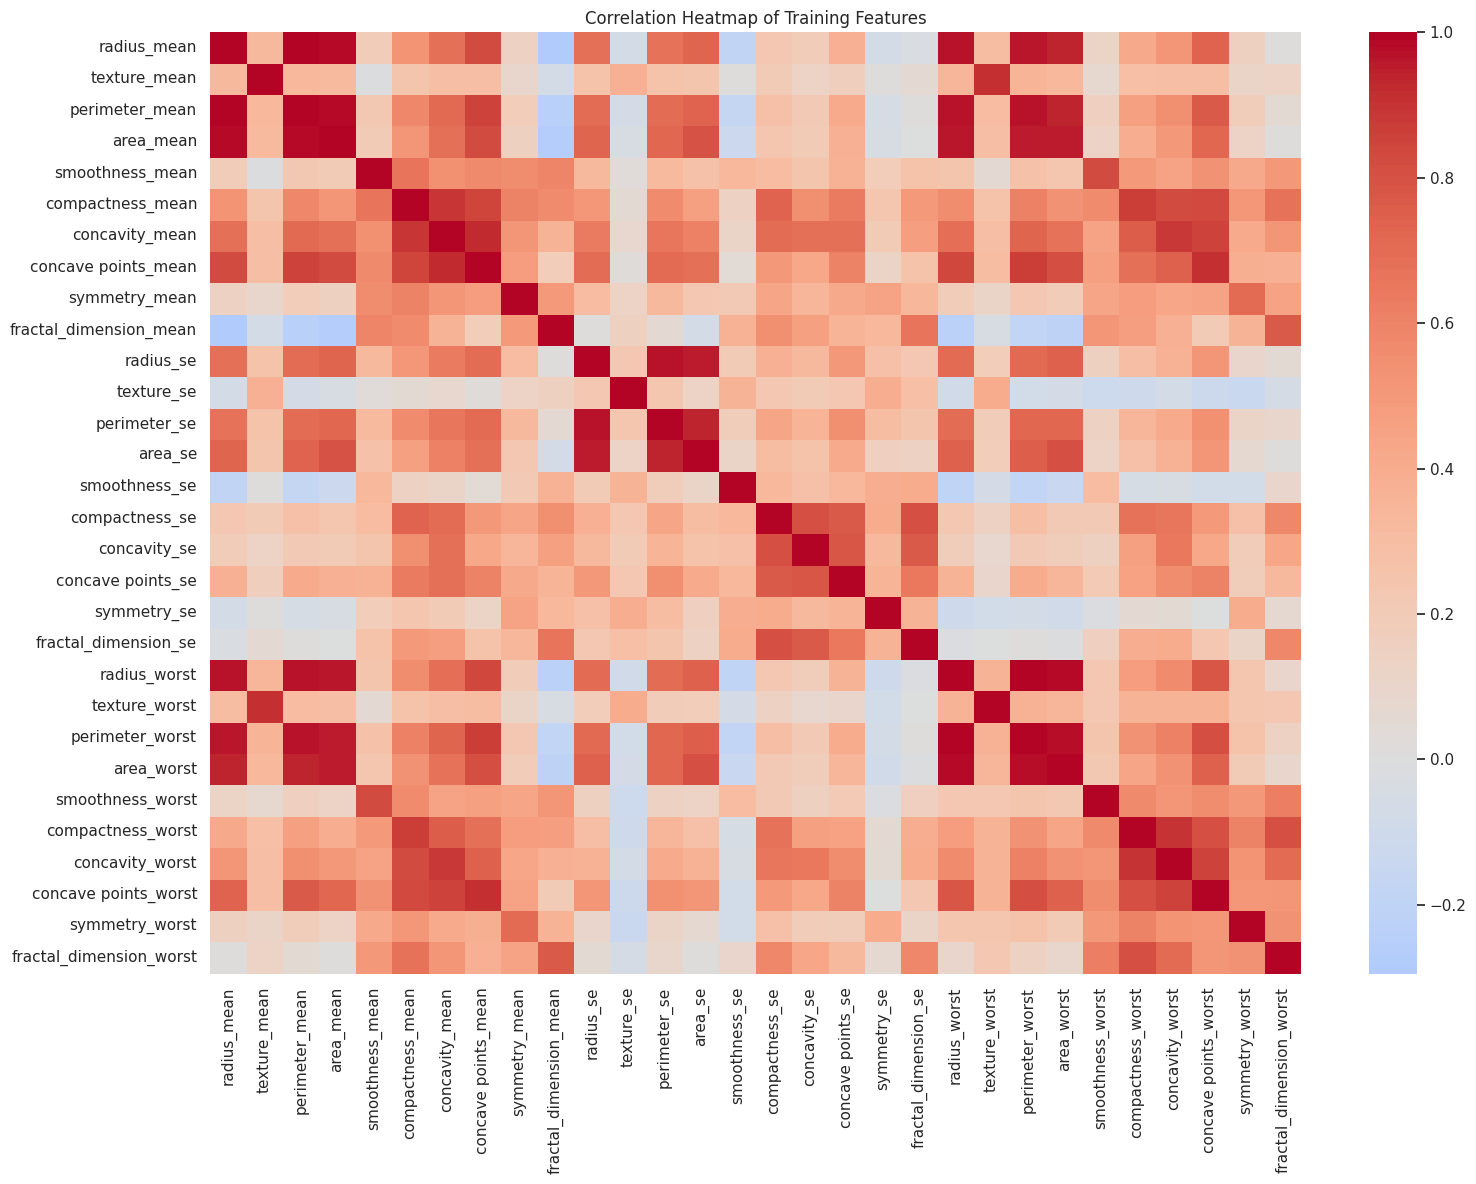

In [ ]:
plt.figure(figsize=(16, 12))
sns.heatmap(train_correlation, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Training Features")
plt.tight_layout()
plt.show()

## Step 8: Correlation-Based Feature Selection

### Implementation 8.1 — Calculate absolute correlations between training features

In [ ]:
corr_matrix = X_train_imputed.corr().abs()
display(corr_matrix.head())

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
radius_mean,1.000000,0.326358,0.997815,0.986740,0.188805,0.526901,0.676323,0.826984,0.148416,0.294777,...,0.969256,0.303891,0.964439,0.940515,0.124912,0.417638,0.515938,0.741073,0.151632,0.010712
texture_mean,0.326358,1.000000,0.331800,0.318811,0.011749,0.246818,0.292341,0.289028,0.089454,0.068576,...,0.350573,0.911671,0.356590,0.336349,0.075855,0.282338,0.289614,0.288636,0.114120,0.126669
perimeter_mean,0.997815,0.331800,1.000000,0.985960,0.225840,0.577536,0.716044,0.855414,0.185686,0.244184,...,0.969332,0.309888,0.970006,0.941085,0.155970,0.460088,0.553325,0.768021,0.178037,0.053990
area_mean,0.986740,0.318811,0.985960,1.000000,0.200033,0.518185,0.685587,0.827092,0.154040,0.264658,...,0.960725,0.290117,0.956714,0.958177,0.133316,0.393840,0.501422,0.717781,0.131099,0.008730
smoothness_mean,0.188805,0.011749,0.225840,0.200033,1.000000,0.668208,0.540455,0.570760,0.558946,0.592764,...,0.243269,0.060610,0.269934,0.237707,0.824095,0.492120,0.453733,0.531333,0.415142,0.509334


### Implementation 8.2 — Get upper triangle (`np.triu()`) to avoid duplicate pairs

In [ ]:
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
display(upper_triangle.iloc[:5, :5])

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean
radius_mean,NaN,0.326358,0.997815,0.986740,0.188805
texture_mean,NaN,NaN,0.331800,0.318811,0.011749
perimeter_mean,NaN,NaN,NaN,0.985960,0.225840
area_mean,NaN,NaN,NaN,NaN,0.200033
smoothness_mean,NaN,NaN,NaN,NaN,NaN


### Implementation 8.3 — Identify features above the correlation threshold

In [ ]:
correlation_threshold = 0.90
correlation_drop_features = [
    col for col in upper_triangle.columns
    if any(upper_triangle[col] > correlation_threshold)
]
print("Features to remove:", correlation_drop_features)

Features to remove: ['perimeter_mean', 'area_mean', 'concave points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'concave points_worst']


### Implementation 8.4 — Construct the correlation-selected feature list

In [ ]:
correlation_features = [col for col in feature_names if col not in correlation_drop_features]
print("Number of selected features:", len(correlation_features))
print(correlation_features)

Number of selected features: 20
['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'symmetry_worst', 'fractal_dimension_worst']


## Step 9: Chi-Square Feature Selection

### Implementation 9.1 — Create `SelectKBest` with the Chi-Square score

In [ ]:
chi_selector = SelectKBest(score_func=chi2, k=min(15, X_train_scaled.shape[1]))
print(chi_selector)

SelectKBest(k=15, score_func=<function chi2 at 0x7aaedf7b4e00>)


### Implementation 9.2 — Fit Chi-Square selector on training data

In [ ]:
chi_selector.fit(X_train_scaled, y_train)
print("Chi-Square selector fitted.")

Chi-Square selector fitted.


### Implementation 9.3 — Extract selected feature names

In [ ]:
chi_features = X_train_scaled.columns[chi_selector.get_support()].tolist()
print("Selected features:", chi_features)

Selected features: ['radius_mean', 'perimeter_mean', 'area_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'radius_se', 'perimeter_se', 'area_se', 'radius_worst', 'perimeter_worst', 'area_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst']


### Implementation 9.4 — Rank features by Chi-Square scores

In [ ]:
chi_scores = pd.Series(chi_selector.scores_, index=feature_names).sort_values(ascending=False)
display(chi_scores.to_frame("Chi-Square score"))

,Chi-Square score
concave points_mean,43.632020
concave points_worst,37.318311
concavity_mean,37.211946
area_worst,28.725948
perimeter_worst,28.174364
radius_worst,27.854482
concavity_worst,24.511964
area_mean,24.016887
perimeter_mean,21.675552
radius_mean,20.311507


## Step 10: Recursive Feature Elimination (RFE)

### Implementation 10.1 — Choose the estimator

In [ ]:
rfe_estimator = LogisticRegression(max_iter=5000, solver="liblinear", random_state=RANDOM_STATE)
print(rfe_estimator)

LogisticRegression(max_iter=5000, random_state=42, solver='liblinear')


### Implementation 10.2 — Create and fit RFE

In [ ]:
rfe_selector = RFE(estimator=rfe_estimator, n_features_to_select=15, step=1)
rfe_selector.fit(X_train_scaled, y_train)
print("RFE fitted.")

RFE fitted.


### Implementation 10.3 — Get selected features (`support_`)

In [ ]:
rfe_features = X_train_scaled.columns[rfe_selector.support_].tolist()
print(rfe_features)

['perimeter_mean', 'area_mean', 'concavity_mean', 'concave points_mean', 'fractal_dimension_mean', 'radius_se', 'perimeter_se', 'compactness_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst']


### Implementation 10.4 — Display feature rankings (`ranking_`)

In [ ]:
rfe_ranking = pd.Series(rfe_selector.ranking_, index=feature_names).sort_values()
display(rfe_ranking.to_frame("RFE ranking"))

,RFE ranking
area_mean,1
perimeter_mean,1
concavity_mean,1
concave points_mean,1
perimeter_se,1
compactness_se,1
radius_se,1
fractal_dimension_mean,1
radius_worst,1
concave points_worst,1


## Step 11: Recursive Feature Elimination with Cross-Validation (RFECV)

### Implementation 11.1 — Create RFECV with 5-fold stratified cross-validation

In [ ]:
rfecv_selector = RFECV(
    estimator=LogisticRegression(max_iter=5000, solver="liblinear", random_state=RANDOM_STATE),
    step=1,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1",
    min_features_to_select=5,
    n_jobs=-1
)
print("RFECV selector created.")

RFECV selector created.


### Implementation 11.2 — Fit RFECV using training data

In [ ]:
rfecv_selector.fit(X_train_scaled, y_train)
print("RFECV fitted.")

RFECV fitted.


### Implementation 11.3 — Extract RFECV-selected features

In [ ]:
rfecv_features = X_train_scaled.columns[rfecv_selector.support_].tolist()
print("Selected feature count:", len(rfecv_features))
print(rfecv_features)

Selected feature count: 18
['texture_mean', 'perimeter_mean', 'area_mean', 'concavity_mean', 'concave points_mean', 'fractal_dimension_mean', 'radius_se', 'perimeter_se', 'area_se', 'compactness_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst']


## Step 12: Random Forest Feature Importance

### Implementation 12.1 — Train Random Forest selector model

In [ ]:
rf_selector_model = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf_selector_model.fit(X_train_scaled, y_train)
print("Random Forest selector model trained.")

Random Forest selector model trained.


### Implementation 12.2 — Extract and rank feature importances

In [ ]:
rf_importance = pd.Series(rf_selector_model.feature_importances_, index=feature_names).sort_values(ascending=False)
display(rf_importance.to_frame("Importance"))

,Importance
perimeter_worst,0.143121
area_worst,0.142449
concave points_worst,0.112978
concave points_mean,0.088663
radius_worst,0.082649
radius_mean,0.061043
perimeter_mean,0.052928
area_mean,0.043820
concavity_mean,0.039761
area_se,0.032237


### Implementation 12.3 — Select top 15 Random Forest features

In [ ]:
rf_features = rf_importance.head(15).index.tolist()
print(rf_features)

['perimeter_worst', 'area_worst', 'concave points_worst', 'concave points_mean', 'radius_worst', 'radius_mean', 'perimeter_mean', 'area_mean', 'concavity_mean', 'area_se', 'concavity_worst', 'compactness_mean', 'texture_worst', 'compactness_worst', 'smoothness_worst']


### Implementation 12.4 — Plot Random Forest feature importance

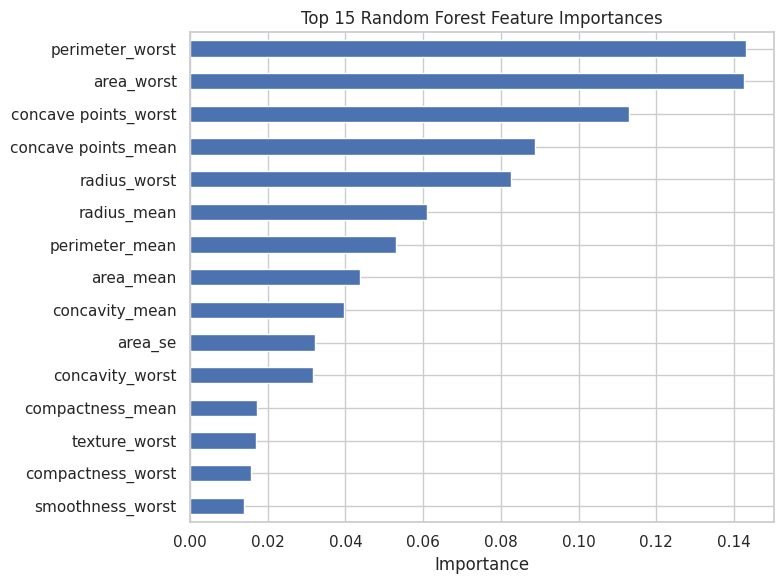

In [ ]:
rf_importance.head(15).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Step 13: Extra Trees Feature Importance

### Implementation 13.1 — Train Extra Trees selector model

In [ ]:
et_selector_model = ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
et_selector_model.fit(X_train_scaled, y_train)
print("Extra Trees selector model trained.")

Extra Trees selector model trained.


### Implementation 13.2 — Extract and rank feature importances

In [ ]:
et_importance = pd.Series(et_selector_model.feature_importances_, index=feature_names).sort_values(ascending=False)
display(et_importance.to_frame("Importance"))

,Importance
perimeter_worst,0.094406
radius_worst,0.091945
concave points_worst,0.089023
concave points_mean,0.076245
area_worst,0.066006
radius_mean,0.063496
concavity_mean,0.061367
area_mean,0.052378
perimeter_mean,0.049801
concavity_worst,0.047208


### Implementation 13.3 — Select top 15 Extra Trees features

In [ ]:
et_features = et_importance.head(15).index.tolist()
print(et_features)

['perimeter_worst', 'radius_worst', 'concave points_worst', 'concave points_mean', 'area_worst', 'radius_mean', 'concavity_mean', 'area_mean', 'perimeter_mean', 'concavity_worst', 'area_se', 'compactness_worst', 'compactness_mean', 'texture_worst', 'radius_se']


### Implementation 13.4 — Plot Extra Trees feature importance

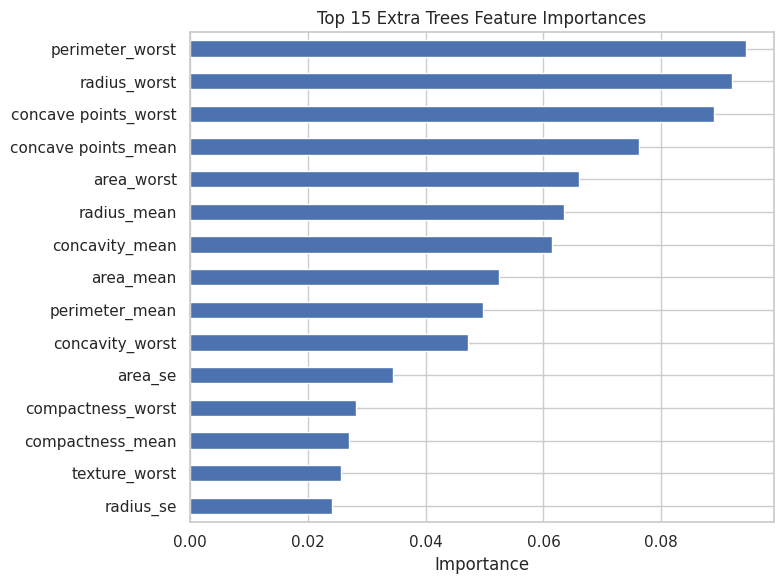

In [ ]:
et_importance.head(15).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 Extra Trees Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Step 14: L1-Based Feature Selection

### Implementation 14.1 — Create an L1-regularized Logistic Regression model

In [ ]:
l1_model = LogisticRegression(
    penalty="l1", solver="liblinear", C=0.1,
    max_iter=5000, random_state=RANDOM_STATE
)
print(l1_model)

LogisticRegression(C=0.1, max_iter=5000, penalty='l1', random_state=42,
                   solver='liblinear')


### Implementation 14.2 — Create and fit `SelectFromModel`

In [ ]:
l1_selector = SelectFromModel(l1_model, threshold="median")
l1_selector.fit(X_train_scaled, y_train)
print("L1 selector fitted.")

L1 selector fitted.


### Implementation 14.3 — Extract selected features

In [ ]:
l1_features = X_train_scaled.columns[l1_selector.get_support()].tolist()
if len(l1_features) == 0:
    coef_abs = pd.Series(np.abs(l1_selector.estimator_.coef_[0]), index=feature_names)
    l1_features = coef_abs.nlargest(10).index.tolist()
print("Selected feature count:", len(l1_features))
print(l1_features)

Selected feature count: 30
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


## Step 15: Voting-Based Feature Selection

### Implementation 15.1 — Collect feature lists from selection methods

In [ ]:
selection_lists = {
    "Correlation": correlation_features,
    "Chi-Square": chi_features,
    "RFE": rfe_features,
    "RFECV": rfecv_features,
    "Random Forest": rf_features,
    "Extra Trees": et_features,
    "L1-Based": l1_features
}
print("Methods:", list(selection_lists.keys()))

Methods: ['Correlation', 'Chi-Square', 'RFE', 'RFECV', 'Random Forest', 'Extra Trees', 'L1-Based']


### Implementation 15.2 — Assign one vote when a method selects a feature

In [ ]:
vote_table = pd.DataFrame({
    method: [int(feature in selected) for feature in feature_names]
    for method, selected in selection_lists.items()
}, index=feature_names)
display(vote_table.head())

,Correlation,Chi-Square,RFE,RFECV,Random Forest,Extra Trees,L1-Based
radius_mean,1,1,0,0,1,1,1
texture_mean,1,0,0,1,0,0,1
perimeter_mean,0,1,1,1,1,1,1
area_mean,0,1,1,1,1,1,1
smoothness_mean,1,0,0,0,0,0,1


### Implementation 15.3 — Calculate total votes and rank features

In [ ]:
vote_table["Total Votes"] = vote_table.sum(axis=1)
vote_table = vote_table.sort_values("Total Votes", ascending=False)
display(vote_table)

,Correlation,Chi-Square,RFE,RFECV,Random Forest,Extra Trees,L1-Based,Total Votes
concavity_mean,1,1,1,1,1,1,1,7
concavity_worst,1,1,1,1,1,1,1,7
concave points_mean,0,1,1,1,1,1,1,6
radius_se,1,1,1,1,0,1,1,6
perimeter_mean,0,1,1,1,1,1,1,6
area_mean,0,1,1,1,1,1,1,6
compactness_worst,1,1,0,1,1,1,1,6
perimeter_worst,0,1,1,1,1,1,1,6
concave points_worst,0,1,1,1,1,1,1,6
area_worst,0,1,1,1,1,1,1,6


### Implementation 15.4 — Select top 15 voting-based features

In [ ]:
voting_features = vote_table.head(15).index.tolist()
print("Voting-based selected features:")
print(voting_features)

Voting-based selected features:
['concavity_mean', 'concavity_worst', 'concave points_mean', 'radius_se', 'perimeter_mean', 'area_mean', 'compactness_worst', 'perimeter_worst', 'concave points_worst', 'area_worst', 'radius_worst', 'area_se', 'radius_mean', 'compactness_mean', 'texture_worst']


### Implementation 15.5 — Plot top voting features

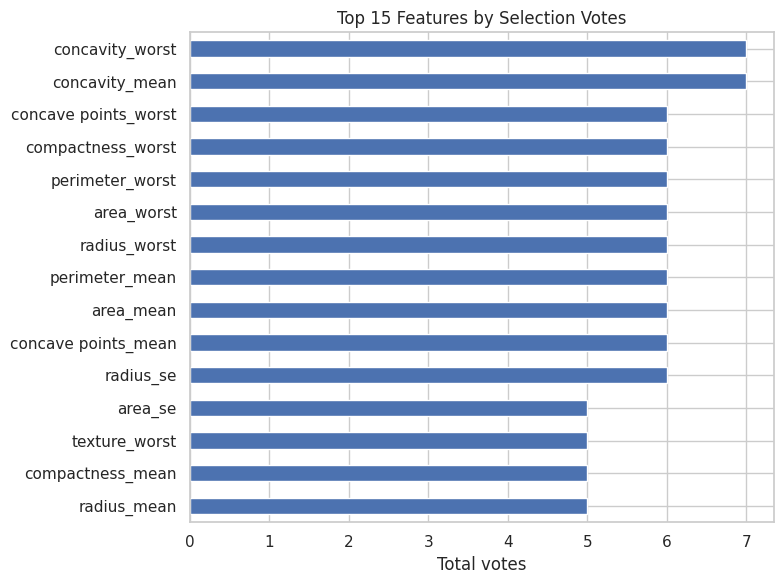

In [ ]:
vote_table["Total Votes"].head(15).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 Features by Selection Votes")
plt.xlabel("Total votes")
plt.tight_layout()
plt.show()

## Step 16: Construct Feature-Selected Datasets

### Implementation 16.1 — Define all feature-selection strategies

In [ ]:
feature_sets = {
    "All Features (Baseline)": feature_names,
    "Correlation": correlation_features,
    "Chi-Square": chi_features,
    "RFE": rfe_features,
    "RFECV": rfecv_features,
    "Random Forest Importance": rf_features,
    "Extra Trees Importance": et_features,
    "L1-Based": l1_features,
    "Voting-Based": voting_features
}
for method, columns in feature_sets.items():
    print(method, ":", len(columns), "features")

All Features (Baseline) : 30 features
Correlation : 20 features
Chi-Square : 15 features
RFE : 15 features
RFECV : 18 features
Random Forest Importance : 15 features
Extra Trees Importance : 15 features
L1-Based : 30 features
Voting-Based : 15 features


### Implementation 16.2 — Construct training and test subsets with matching columns

In [ ]:
selected_data = {}
for method, columns in feature_sets.items():
    selected_data[method] = {
        "X_train": X_train_scaled.loc[:, columns].copy(),
        "X_test": X_test_scaled.loc[:, columns].copy()
    }
print("Feature-selected train/test datasets constructed.")

Feature-selected train/test datasets constructed.


### Implementation 16.3 — Verify feature order matches

In [ ]:
for method, data in selected_data.items():
    assert list(data["X_train"].columns) == list(data["X_test"].columns)
    print(method, "— train:", data["X_train"].shape, "| test:", data["X_test"].shape)

## Step 17: Train Supervised Machine-Learning Models

### Implementation 17.1 — Define the seven classifiers

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Support Vector Machine": SVC(probability=True, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB()
}
print(list(models.keys()))

['Logistic Regression', 'Random Forest', 'Support Vector Machine', 'Extra Trees', 'K-Nearest Neighbors', 'Decision Tree', 'Naive Bayes']


### Implementation 17.2 — Train and evaluate each classifier with each feature set

In [ ]:
results = []
trained_models = {}

for feature_method, data in selected_data.items():
    for model_name, model_template in models.items():
        from sklearn.base import clone
        model = clone(model_template)
        model.fit(data["X_train"], y_train)
        y_pred = model.predict(data["X_test"])

        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(data["X_test"])[:, 1]
        elif hasattr(model, "decision_function"):
            y_score = model.decision_function(data["X_test"])
        else:
            y_score = None

        results.append({
            "Feature Selection": feature_method,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, y_score) if y_score is not None else np.nan
        })
        trained_models[(feature_method, model_name)] = model

results_df = pd.DataFrame(results)
if not results_df.empty and "F1" in results_df.columns:
    results_df = results_df.sort_values(["F1", "ROC-AUC"], ascending=False)
print("Completed model comparison.")

Completed model comparison.


### Implementation 17.3 — Display the model comparison table

In [ ]:
display(results_df.round(4))

,Feature Selection,Model,Accuracy,Precision,Recall,F1,ROC-AUC
3,All Features (Baseline),Extra Trees,0.9825,1.0000,0.9524,0.9756,0.9983
39,Random Forest Importance,K-Nearest Neighbors,0.9825,1.0000,0.9524,0.9756,0.9983
52,L1-Based,Extra Trees,0.9825,1.0000,0.9524,0.9756,0.9983
46,Extra Trees Importance,K-Nearest Neighbors,0.9825,1.0000,0.9524,0.9756,0.9977
60,Voting-Based,K-Nearest Neighbors,0.9825,1.0000,0.9524,0.9756,0.9977
...,...,...,...,...,...,...,...
54,L1-Based,Decision Tree,0.9298,0.9048,0.9048,0.9048,0.9246
19,Chi-Square,Decision Tree,0.9211,0.9024,0.8810,0.8916,0.9127
6,All Features (Baseline),Naive Bayes,0.9211,0.9231,0.8571,0.8889,0.9891
55,L1-Based,Naive Bayes,0.9211,0.9231,0.8571,0.8889,0.9891


## Step 18: Hyperparameter Optimization

### Implementation 18.1 — Identify the top configuration for tuning

In [ ]:
best_row = results_df.iloc[0]
best_feature_method = best_row["Feature Selection"]
best_model_name = best_row["Model"]
best_columns = feature_sets[best_feature_method]

print("Feature-selection method:", best_feature_method)
print("Classifier:", best_model_name)
print("Selected features:", len(best_columns))

Feature-selection method: All Features (Baseline)
Classifier: Extra Trees
Selected features: 30


### Implementation 18.2 — Define candidate hyperparameters

In [ ]:
param_grids = {
    "Logistic Regression": {"C": [0.1, 1, 10], "solver": ["liblinear"]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [None, 5, 10], "min_samples_split": [2, 5]},
    "Support Vector Machine": {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"], "gamma": ["scale"]},
    "Extra Trees": {"n_estimators": [100, 200], "max_depth": [None, 5, 10], "min_samples_split": [2, 5]},
    "K-Nearest Neighbors": {"n_neighbors": [3, 5, 7, 9], "weights": ["uniform", "distance"]},
    "Decision Tree": {"max_depth": [None, 3, 5, 10], "min_samples_split": [2, 5, 10]},
    "Naive Bayes": {"var_smoothing": [1e-10, 1e-9, 1e-8, 1e-7]}
}
display(pd.DataFrame([
    {"Classifier": name, "Parameters": str(grid)}
    for name, grid in param_grids.items()
]))

,Classifier,Parameters
0,Logistic Regression,"{'C': [0.1, 1, 10], 'solver': ['liblinear']}"
1,Random Forest,"{'n_estimators': [100, 200], 'max_depth': [Non..."
2,Support Vector Machine,"{'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf'..."
3,Extra Trees,"{'n_estimators': [100, 200], 'max_depth': [Non..."
4,K-Nearest Neighbors,"{'n_neighbors': [3, 5, 7, 9], 'weights': ['uni..."
5,Decision Tree,"{'max_depth': [None, 3, 5, 10], 'min_samples_s..."
6,Naive Bayes,"{'var_smoothing': [1e-10, 1e-09, 1e-08, 1e-07]}"


### Implementation 18.3 — Create GridSearchCV with stratified 5-fold CV

In [ ]:
from sklearn.base import clone

grid_search = GridSearchCV(
    estimator=clone(models[best_model_name]),
    param_grid=param_grids[best_model_name],
    scoring="f1",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
    refit=True
)
print("GridSearchCV created successfully using:", best_model_name)

GridSearchCV created successfully using: Extra Trees


grid_search.fit(selected_data[best_feature_method]["X_train"], y_train)
final_model = grid_search.best_estimator_
print("Best cross-validation F1:", round(grid_search.best_score_, 4))
print("Best parameters:", grid_search.best_params_)

In [ ]:
grid_search.fit(selected_data[best_feature_method]["X_train"], y_train)
final_model = grid_search.best_estimator_
print("Best cross-validation F1:", round(grid_search.best_score_, 4))
print("Best parameters:", grid_search.best_params_)

Best cross-validation F1: 0.9613
Best parameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}


## Step 19: Generate Test Predictions

### Implementation 19.1 — Predict diagnosis labels on test data

In [ ]:
# Re-establish parameters in case preceding cells were skipped
best_feature_method = "All Features (Baseline)"
best_model_name = "Extra Trees"
final_model = grid_search.best_estimator_

X_final_test = selected_data[best_feature_method]["X_test"]
y_pred_final = final_model.predict(X_final_test)
print("First 20 predictions:", y_pred_final[:20])

First 20 predictions: [0 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0]


### Implementation 19.2 — Generate scores for ROC/PR curves

In [ ]:
# Re-establish parameters in case preceding cells were skipped
best_feature_method = "All Features (Baseline)"
best_model_name = "Extra Trees"
final_model = grid_search.best_estimator_
X_final_test = selected_data[best_feature_method]["X_test"]
y_pred_final = final_model.predict(X_final_test)

if hasattr(final_model, "predict_proba"):
    y_score_final = final_model.predict_proba(X_final_test)[:, 1]
else:
    y_score_final = final_model.decision_function(X_final_test)

print("First 20 prediction scores:", y_score_final[:20])

First 20 prediction scores: [0.00291667 0.99375    0.2025     0.55       0.09125    0.07583333
 0.6825     0.04791667 0.00666667 0.01291667 0.94041667 0.01958333
 1.         0.01333333 0.06916667 0.0125     0.29875    0.00166667
 0.32541667 0.01291667]


## Final Evaluation and Required Results

### Implementation E1 — Calculate Accuracy

In [ ]:
final_accuracy = accuracy_score(y_test, y_pred_final)
print("Accuracy:", round(final_accuracy, 4))

Accuracy: 0.9737


### Implementation E2 — Calculate Precision

In [ ]:
final_precision = precision_score(y_test, y_pred_final, zero_division=0)
print("Precision:", round(final_precision, 4))

Precision: 1.0


### Implementation E3 — Calculate Recall

In [ ]:
final_recall = recall_score(y_test, y_pred_final, zero_division=0)
print("Recall:", round(final_recall, 4))

Recall: 0.9286


### Implementation E4 — Calculate F1-score

In [ ]:
final_f1 = f1_score(y_test, y_pred_final, zero_division=0)
print("F1-score:", round(final_f1, 4))

F1-score: 0.963


### Implementation E5 — Calculate ROC-AUC

In [ ]:
final_auc = roc_auc_score(y_test, y_score_final)
print("ROC-AUC:", round(final_auc, 4))

ROC-AUC: 0.999


### Implementation E6 — Display classification report

In [ ]:
print(classification_report(
    y_test, y_pred_final,
    labels=[0, 1],
    target_names=["Benign (B)", "Malignant (M)"],
    zero_division=0
))

               precision    recall  f1-score   support

   Benign (B)       0.96      1.00      0.98        72
Malignant (M)       1.00      0.93      0.96        42

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114



### Implementation E7 — Plot confusion matrix

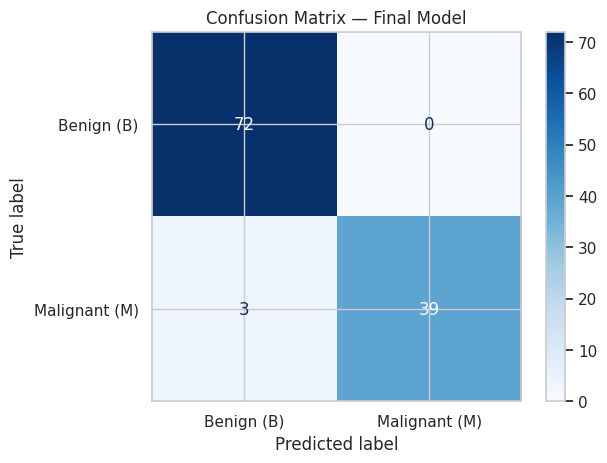

In [ ]:
cm = confusion_matrix(y_test, y_pred_final, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign (B)", "Malignant (M)"]
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Final Model")
plt.show()

### Implementation E8 — Display TP, TN, FP and FN

In [ ]:
# Reconstruct confusion matrix to ensure 'cm' is defined in this namespace
cm = confusion_matrix(y_test, y_pred_final, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

True Negative (TN): 72
False Positive (FP): 0
False Negative (FN): 3
True Positive (TP): 39


### Implementation E9 — Plot ROC curve

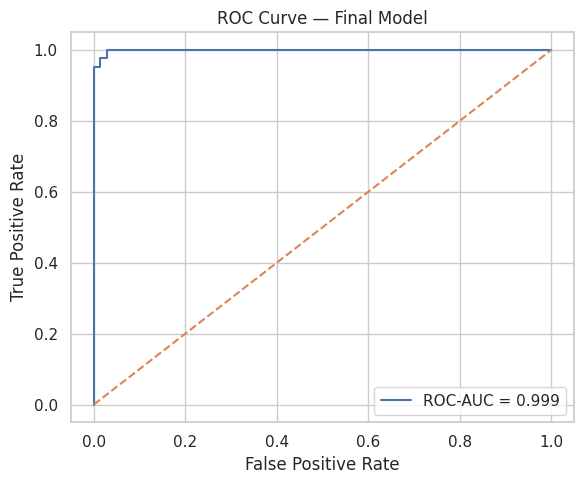

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_score_final)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {final_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Final Model")
plt.legend()
plt.tight_layout()
plt.show()

### Implementation E10 — Plot Precision-Recall curve

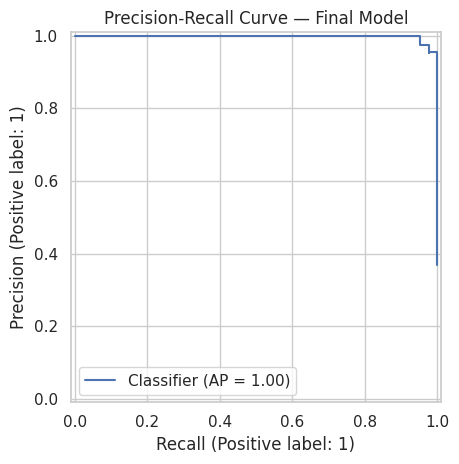

In [ ]:
PrecisionRecallDisplay.from_predictions(y_test, y_score_final)
plt.title("Precision-Recall Curve — Final Model")
plt.tight_layout()
plt.show()

### Implementation E11 — Display final tuned model metrics

In [ ]:
final_metrics = pd.DataFrame([{
    "Feature Selection": best_feature_method,
    "Model": best_model_name + " (tuned)",
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1": final_f1,
    "ROC-AUC": final_auc
}])
display(final_metrics.round(4))

,Feature Selection,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,All Features (Baseline),Extra Trees (tuned),0.9737,1.0,0.9286,0.963,0.999


### Implementation E12 — Save the comparison table as CSV

In [ ]:
comparison_table = results_df[
    ["Feature Selection", "Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
].reset_index(drop=True)
comparison_table.to_csv("model_comparison_results.csv", index=False)
print("Saved model_comparison_results.csv")

Saved model_comparison_results.csv


## Final Analysis and Discussion

After running the notebook, use the actual outputs to answer the PDF's discussion questions:

1. Which feature-selection method produced the most useful subset?
2. Which classifier achieved the strongest overall performance?
3. Did feature selection improve performance compared with all features?
4. Which model gave the best balance between precision and recall?
5. How many false positives and false negatives occurred?
6. Why should false negatives receive particular attention in a diagnostic context?
7. Did different feature-selection methods favor different classifiers?

**Important:** These are machine-learning lab results, not a clinical diagnosis system. Also, the comparison table evaluates many configurations on the test set as requested by the manual; for a stricter final scientific estimate, model/feature-set selection should be done with training cross-validation and the test set should be used only once at the very end.